# MoCo (SSL) cho EfficientNetB0 trên ảnh X-quang ngực — ImageNet → MoCo-CXR

Notebook này pretrain **EfficientNetB0 bằng MoCo v2** theo công thức của repo [stanfordmlgroup/MoCo-CXR](https://github.com/stanfordmlgroup/MoCo-CXR) (`main_moco.py` + `moco/builder.py` + `moco/loader.py` + `aihc_utils/image_transform.py`), rồi xuất **backbone** để nạp vào notebook B0/B0+CA hiện có.

**Cấu hình thí nghiệm:** khởi tạo B0 từ **ImageNet**, SSL trên **CheXpert (ảnh frontal) + NIH-train** (chỉ tập train của split theo bệnh nhân, **không** dùng val/test). Đặt `FROM_IMAGENET = False` để chạy bản "MoCo từ đầu" làm đối chứng.

## Giữ nguyên so với repo
- Query encoder + key encoder (cập nhật momentum `m=0.999`) + hàng đợi `K` khóa âm, loss InfoNCE, `T=0.07`, `dim=128`.
- Đầu MLP của MoCo v2 (`Linear → ReLU → Linear`), khởi tạo từ ImageNet (`--from-imagenet`).
- Augmentation `chexpert` của repo: xoay ±10° + dịch nhẹ (thay cho `RandomCrop`), **không** dùng color jitter/blur. Phép **lật ngang** của repo được **tắt mặc định** (`AUG_HFLIP = False`) để nhất quán với notebook B0 của bạn (downstream không lật vì vị trí tim/phổi mang thông tin); bật lại nếu muốn bám đúng repo.
- Adam `lr=1e-4`, `weight_decay=1e-4` (L2 cộng vào gradient như `torch.optim.Adam`), 20 epoch, giảm LR ×0.1 tại epoch 12 và 18.
- Chỉ xuất **backbone của query encoder** (bỏ đầu MLP, queue, key encoder) — giống cách `main_lincls.py` chỉ nạp `encoder_q` trừ `fc`.

## Khác repo (có chủ ý)
| Mục | Repo | Notebook này | Lý do |
|---|---|---|---|
| Framework | PyTorch | **tf_keras (Keras 2)** | Notebook B0 của bạn là tf_keras → nạp thẳng trọng số `.h5`, không phải chuyển PyTorch→Keras (dễ lỗi padding/BN) |
| GPU | DDP nhiều GPU | 1 GPU | Kaggle. Shuffle-BN của repo chỉ hoạt động khi có ≥ 2 tiến trình; trên 1 GPU nó vô tác dụng. Ở đây mô phỏng bằng **BN theo nhóm nhỏ** (`BN_CHUNK`) + xáo trộn batch của key encoder |
| Ảnh | 320 px | **224 px** | Khớp notebook B0 |
| Batch / K | 24 / 24576 | 128 / 16384 | B0 nhỏ, dùng AMP; `K` phải chia hết cho batch |
| Dữ liệu | CheXpert | CheXpert + NIH-train | Theo kế hoạch thí nghiệm |

## Lưu ý quan trọng về thang đầu vào và cấu trúc backbone
- `EfficientNetB0` của Keras đã có sẵn lớp `Rescaling(1/255)` + `Normalization` bên trong, nên ảnh phải vào ở **thang 0–255**. Notebook B0 mới (`INPUT_RESCALE = None`) đã làm đúng như vậy, vì thế `FEED_RANGE = '0-255'` là mặc định ở đây. Chỉ dùng `'0-1'` nếu downstream vẫn còn `rescale=1./255`. Thang đầu vào của pretrain và downstream **phải giống nhau**.
- Keras chỉ chèn thêm phép nhân `1/sqrt(std)` sau `Normalization` khi dựng với `weights='imagenet'`. Vì vậy khi nạp backbone vào downstream, hãy dựng `EfficientNetB0` với **cùng `weights`** như lúc pretrain (xem §6, §7).

## Quy trình
Cấu hình → §1 danh sách ảnh SSL (CheXpert frontal + NIH-train theo đúng split của notebook B0) → §2 pipeline `tf.data` + augmentation trên GPU → §3 mô hình MoCo → §4 (tùy chọn) linear-probe kiểm tra nhanh trên NIH val → §5 huấn luyện có checkpoint/resume → §6 xuất và kiểm tra backbone → §7 cách nạp vào notebook B0.

In [1]:
# [KAGGLE] Dùng Keras 2 (tf_keras) như notebook B0. Biến môi trường này PHẢI đặt trước khi import tensorflow.
import os, sys, subprocess, importlib.metadata as _md
os.environ["TF_USE_LEGACY_KERAS"] = "1"
if "tensorflow" in sys.modules:
    print("CẢNH BÁO: tensorflow đã được import trước cell này -> Restart session rồi chạy lại từ cell đầu.")
try:
    import tf_keras
except ImportError:
    _tfv = ".".join(_md.version("tensorflow").split(".")[:2])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"tf_keras~={_tfv}.0"])
    import tf_keras
print("tensorflow", _md.version("tensorflow"), "| tf_keras", _md.version("tf_keras"))

tensorflow 2.20.0 | tf_keras 2.20.1


In [2]:
# =====================================================================
#                              CẤU HÌNH
# =====================================================================
# ---- Đường dẫn (Kaggle) ----
CHEXPERT_ROOT = None    # None = tự tìm thư mục chứa train.csv dưới /kaggle/input (vd /kaggle/input/datasets/ashery/chexpert)
NIH_IMG_DIR   = '/kaggle/input/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized'      # như notebook B0
NIH_CSV       = '/kaggle/input/datasets/nih-chest-xrays/data/Data_Entry_2017.csv'            # như notebook B0
NIH_TRAIN_VAL_LIST = None   # None = tự tìm train_val_list.txt cạnh CSV
NIH_TEST_LIST      = None   # None = tự tìm test_list.txt cạnh CSV
OUT_DIR    = '/kaggle/working/moco_b0'
RESUME_DIR = '/kaggle/input/notebooks/huynhlhna/moco-efficientnetb0/moco_b0/ckpt'       # thư mục 'ckpt' của lần chạy trước (vd '/kaggle/input/<ten-output>/moco_b0/ckpt') để chạy tiếp; None = chạy mới

# ---- Dữ liệu SSL (nhãn KHÔNG được dùng ở bước này) ----
USE_CHEXPERT        = True
USE_NIH_TRAIN       = True    # chỉ tập train của split theo bệnh nhân (giống notebook B0)
NIH_REPEAT          = 1       # lặp NIH-train k lần mỗi epoch để tăng tỉ trọng dữ liệu cùng miền (1 = không lặp)
CHEXPERT_MAX_IMAGES = None    # lấy mẫu ngẫu nhiên tối đa N ảnh CheXpert để chạy nhanh; None = dùng hết (~191k ảnh frontal)

# ---- Mô hình ----
FROM_IMAGENET = True          # True = ImageNet -> MoCo ; False = MoCo từ đầu (đối chứng)
IMG_SIZE      = 224
FEED_RANGE    = '0-255'       # '0-255' = khớp notebook B0 mới (INPUT_RESCALE=None, Keras tự rescale bên trong) ; '0-1' chỉ dùng nếu downstream vẫn rescale=1./255
MOCO_DIM, MOCO_K, MOCO_M, MOCO_T = 128, 16384, 0.999, 0.07
USE_MLP_HEAD  = True          # MoCo v2 (--mlp)

# ---- Huấn luyện ----
BATCH_SIZE   = 128            # nếu OOM: giảm còn 64 (MOCO_K vẫn phải chia hết cho batch)
BN_CHUNK     = 32             # số ảnh mỗi nhóm BN (mô phỏng BN theo GPU của MoCo); BATCH_SIZE phải chia hết cho BN_CHUNK
EPOCHS       = 20
LR           = 1e-4
WEIGHT_DECAY = 1e-4
LR_SCHEDULE  = [12, 18]       # giảm LR x0.1 tại các epoch này
AUG_PRESET   = 'chexpert'     # 'chexpert' = như repo (xoay + dịch, lật tùy AUG_HFLIP) ; 'cxr_strong' = thêm zoom-in + brightness/contrast
AUG_HFLIP    = False          # repo MoCo-CXR có lật ngang; notebook B0 của bạn TẮT lật (vị trí tim/phổi mang thông tin) -> mặc định tắt cho nhất quán
USE_AMP      = False
SEED         = 2018
TIME_BUDGET_HOURS = 11.0      # dừng sạch (đã lưu checkpoint) nếu epoch kế tiếp có thể vượt ngân sách giờ của phiên Kaggle
PRINT_EVERY  = 100            # in log mỗi N bước
MAX_STEPS_PER_EPOCH = None    # chỉ để gỡ lỗi nhanh (vd 50); None = chạy trọn epoch

# ---- Linear-probe kiểm tra nhanh (trên NIH; dùng train/val, KHÔNG dùng test) ----
RUN_PROBE     = True
PROBE_TRAIN_N = 8000
PROBE_VAL_N   = 4000
PROBE_EVERY   = 5             # epoch; luôn chạy thêm ở epoch cuối
SAVE_BACKBONE_EVERY = 5       # lưu thêm backbone_epXX.h5 mỗi N epoch (để chọn epoch tốt nhất sau này)

In [3]:
import gc, glob, json, math, random, time, warnings
from itertools import chain
import numpy as np
import pandas as pd
import tensorflow as tf
assert tf.keras.Model.__module__.startswith("tf_keras"), "tf.keras không phải Keras 2 -> kiểm tra TF_USE_LEGACY_KERAS / tf_keras"
layers = tf.keras.layers
warnings.filterwarnings("ignore")

assert MOCO_K % BATCH_SIZE == 0, "MOCO_K phải chia hết cho BATCH_SIZE (như assert trong moco/builder.py)"
assert BATCH_SIZE % BN_CHUNK == 0, "BATCH_SIZE phải chia hết cho BN_CHUNK"
assert FEED_RANGE in ('0-1', '0-255') and AUG_PRESET in ('chexpert', 'cxr_strong')

os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
print('GPU:', gpus if gpus else 'KHÔNG CÓ GPU -> sẽ rất chậm, hãy bật Accelerator')
if USE_AMP:
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
print('Mixed precision policy:', tf.keras.mixed_precision.global_policy().name)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Mixed precision policy: float32


## 1. Danh sách ảnh cho SSL
- **CheXpert** (`ashery/chexpert`, bản small): chỉ lấy ảnh **Frontal** có `AP/PA` ∈ {AP, PA} (bỏ 17 ảnh bị gắn nhãn Frontal nhưng `AP/PA` là LL/RL), vì NIH chỉ có ảnh thẳng. Nhãn CheXpert **không** được dùng.
- **NIH-train**: dựng lại **đúng các bước lọc và split** của notebook B0 (lọc `Patient Age < 100`, bỏ tổ hợp nhãn ≤ 11 ảnh, `train_val_list.txt` chia 80/20 bằng `GroupShuffleSplit(random_state=2018)` theo `Patient ID`). Chỉ phần **train** đi vào SSL; val và test không bao giờ được đọc ở bước SSL (có assert kiểm tra).

In [4]:
def _find_root(base, marker, max_depth=5):
    for dirpath, dirnames, filenames in os.walk(base):
        depth = dirpath[len(base):].count(os.sep)
        if marker in filenames:
            return dirpath
        if depth >= max_depth:
            dirnames[:] = []
    raise FileNotFoundError(f"Không thấy {marker} dưới {base} -> hãy Add Data hoặc đặt đường dẫn thủ công ở cell cấu hình.")

# ------------------------------------------------------------------ CheXpert (frontal)
cx = None
if USE_CHEXPERT:
    cx_root = CHEXPERT_ROOT or _find_root('/kaggle/input', 'train.csv')
    cx = pd.read_csv(os.path.join(cx_root, 'train.csv'))
    assert 'Frontal/Lateral' in cx.columns, f"{cx_root}/train.csv không giống CheXpert"
    n_all = len(cx)
    cx = cx[(cx['Frontal/Lateral'] == 'Frontal') & (cx['AP/PA'].isin(['AP', 'PA']))].copy()
    # CSV ghi 'CheXpert-v1.0-small/train/...', thư mục thật trên Kaggle có thể không còn tiền tố đó -> tự dò cách ghép
    _probe_p = cx['Path'].iloc[0]
    _resolvers = [lambda p: os.path.join(cx_root, p),
                  lambda p: os.path.join(cx_root, *p.split('/')[1:]),
                  lambda p: os.path.join(os.path.dirname(cx_root), p)]
    _resolve = next((f for f in _resolvers if os.path.exists(f(_probe_p))), None)
    assert _resolve is not None, "Không ghép được cột Path với thư mục ảnh CheXpert"
    cx['path'] = cx['Path'].map(_resolve)
    _ok = cx['path'].sample(min(2000, len(cx)), random_state=SEED).map(os.path.exists)
    assert _ok.all(), f"Có {int((~_ok).sum())}/{len(_ok)} ảnh CheXpert mẫu không tồn tại -> kiểm tra cách ghép đường dẫn"
    cx['patient'] = 'cx_' + cx['Path'].str.extract(r'(patient\d+)')[0]
    if CHEXPERT_MAX_IMAGES and len(cx) > CHEXPERT_MAX_IMAGES:
        cx = cx.sample(CHEXPERT_MAX_IMAGES, random_state=SEED)
    cx['source'] = 'chexpert'
    print(f'CheXpert: {len(cx):,}/{n_all:,} ảnh frontal (AP/PA) | {cx.patient.nunique():,} bệnh nhân | root={cx_root}')

# ------------------------------------------------------------------ NIH-train (đúng split của notebook B0)
nih_train = train_df = valid_df = test_df = all_labels = None
if USE_NIH_TRAIN or RUN_PROBE:
    from sklearn.model_selection import GroupShuffleSplit
    assert os.path.isfile(NIH_CSV), f"Không thấy NIH_CSV = {NIH_CSV}"
    csv_dir = os.path.dirname(NIH_CSV)

    def _find_list(name, given):
        if given:
            assert os.path.isfile(given), f'Không thấy {given}'
            return given
        for d in (csv_dir, NIH_IMG_DIR, '/kaggle/input/datasets/nih-chest-xrays/data', '/kaggle/input/data', '/kaggle/input/nih-chest-xrays/data'):
            hits = sorted(glob.glob(os.path.join(d, '**', name), recursive=True)) if os.path.isdir(d) else []
            if hits:
                return hits[0]
        raise FileNotFoundError(f'Không thấy {name} -> đặt NIH_TRAIN_VAL_LIST / NIH_TEST_LIST ở cell cấu hình')
    tv_path = _find_list('train_val_list.txt', NIH_TRAIN_VAL_LIST)
    te_path = _find_list('test_list.txt', NIH_TEST_LIST)

    data = pd.read_csv(NIH_CSV)
    data['Patient Age'] = pd.to_numeric(data['Patient Age'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
    data = data[data['Patient Age'] < 100]
    data = data[['Image Index', 'Finding Labels', 'Patient ID']]

    _paths = {}
    for x in glob.glob(os.path.join(NIH_IMG_DIR, '**', '*'), recursive=True):
        if x.lower().endswith(('.png', '.jpg', '.jpeg')):
            _paths[os.path.splitext(os.path.basename(x))[0]] = x
    assert _paths, f'Không thấy ảnh trong {NIH_IMG_DIR}'
    data['Path'] = data['Image Index'].map(lambda n: _paths.get(os.path.splitext(n)[0]))
    assert data['Path'].notna().all(), f"{int(data['Path'].isna().sum())} dòng CSV không có ảnh tương ứng"

    all_labels = sorted(set(chain(*data['Finding Labels'].map(lambda s: s.split('|')))) - {'No Finding'})
    data = data.groupby('Finding Labels').filter(lambda x: len(x) > 11)      # bỏ tổ hợp nhãn <= 11 ảnh (như paper)

    def _read_list(p):
        with open(p) as f:
            return set(l.strip() for l in f if l.strip())
    tv_names, te_names = _read_list(tv_path), _read_list(te_path)
    assert not (tv_names & te_names)
    tv_df   = data[data['Image Index'].isin(tv_names)]
    test_df = data[data['Image Index'].isin(te_names)]
    _tr, _va = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=2018).split(tv_df, groups=tv_df['Patient ID']))
    train_df, valid_df = tv_df.iloc[_tr], tv_df.iloc[_va]

    # Kiểm tra rò rỉ: không bệnh nhân / ảnh nào của val-test lọt vào tập train dùng cho SSL
    P_ = {'train': set(train_df['Patient ID']), 'valid': set(valid_df['Patient ID']), 'test': set(test_df['Patient ID'])}
    for a, b in (('train', 'valid'), ('train', 'test'), ('valid', 'test')):
        assert not (P_[a] & P_[b]), f'Rò rỉ bệnh nhân giữa {a} và {b}'
    assert not (set(train_df['Image Index']) & (set(valid_df['Image Index']) | set(test_df['Image Index'])))
    print(f'NIH: train {len(train_df):,} | valid {len(valid_df):,} | test {len(test_df):,} ảnh '
          f'| bệnh nhân train/valid/test: {len(P_["train"]):,}/{len(P_["valid"]):,}/{len(P_["test"]):,}')
    print('NIH: split khớp notebook B0 (cùng bộ lọc + GroupShuffleSplit random_state=2018), không rò rỉ bệnh nhân.')
    if USE_NIH_TRAIN:
        nih_train = train_df[['Path', 'Patient ID']].rename(columns={'Path': 'path', 'Patient ID': 'patient'}).copy()
        nih_train['patient'] = 'nih_' + nih_train['patient'].astype(str)
        nih_train['source'] = 'nih_train'

# ------------------------------------------------------------------ Gộp
parts = [d[['path', 'patient', 'source']] for d in (cx, nih_train) if d is not None]
assert parts, 'Phải bật ít nhất một nguồn dữ liệu SSL'
manifest = pd.concat(parts, ignore_index=True)
manifest.to_csv(os.path.join(OUT_DIR, 'ssl_manifest.csv'), index=False)      # lưu lại để tái lập / viết báo cáo
ssl_df = pd.concat([manifest] + [manifest[manifest.source == 'nih_train']] * max(0, NIH_REPEAT - 1), ignore_index=True)
STEPS_PER_EPOCH = len(ssl_df) // BATCH_SIZE
print('\nThành phần dữ liệu SSL mỗi epoch:'); print(ssl_df['source'].value_counts().to_string())
print(f'Tổng {len(ssl_df):,} ảnh -> {STEPS_PER_EPOCH:,} bước/epoch (batch {BATCH_SIZE}); manifest: {OUT_DIR}/ssl_manifest.csv')

CheXpert: 191,010/223,414 ảnh frontal (AP/PA) | 64,534 bệnh nhân | root=/kaggle/input/datasets/ashery/chexpert
NIH: train 68,080 | valid 17,508 | test 24,804 ảnh | bệnh nhân train/valid/test: 22,340/5,586/2,784
NIH: split khớp notebook B0 (cùng bộ lọc + GroupShuffleSplit random_state=2018), không rò rỉ bệnh nhân.

Thành phần dữ liệu SSL mỗi epoch:
source
chexpert     191010
nih_train     68080
Tổng 259,090 ảnh -> 2,024 bước/epoch (batch 128); manifest: /kaggle/working/moco_b0/ssl_manifest.csv


## 2. Pipeline dữ liệu và augmentation
Mỗi ảnh chỉ được **giải mã một lần** trên CPU (`tf.data`), sau đó **hai view ngẫu nhiên (query/key) được tạo trên GPU** từ cùng một batch. Cách này tránh nghẽn CPU khi Kaggle chỉ có vài nhân. Ảnh CheXpert (≈ 390×320) được resize thẳng về 224×224 để toàn bộ vùng ngực nằm trọn trong khung vuông, gần với ảnh NIH 224×224 mà downstream sử dụng (thay vì cắt `RandomCrop` làm mất rìa và phóng to vùng ngực).

I0000 00:00:1792293493.193083      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792293493.196361      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


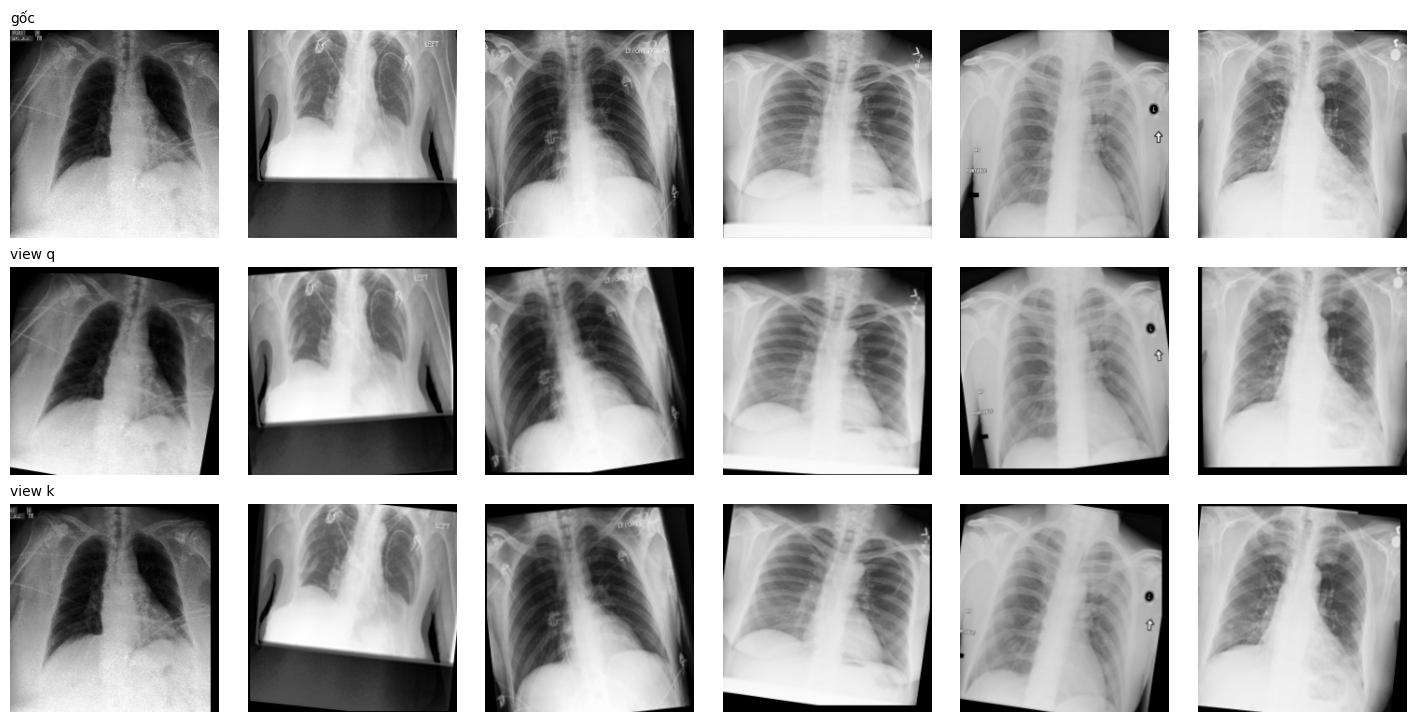

batch (8, 224, 224, 1) <dtype: 'uint8'> | ảnh 224 px | thang đưa vào mô hình: 0-255


In [5]:
def load_image(path):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=1, expand_animations=False)          # uint8 (H, W, 1)
    img.set_shape([None, None, 1])
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE], method='bilinear', antialias=True)
    return tf.cast(tf.round(tf.clip_by_value(img, 0.0, 255.0)), tf.uint8)

def make_dataset(paths, batch_size, shuffle=True, drop_remainder=True, deterministic=False):
    ds = tf.data.Dataset.from_tensor_slices(np.asarray(paths, dtype=object))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.ignore_errors() if hasattr(ds, 'ignore_errors') else ds.apply(tf.data.experimental.ignore_errors())
    ds = ds.batch(batch_size, drop_remainder=drop_remainder).prefetch(tf.data.AUTOTUNE)
    opts = tf.data.Options(); opts.deterministic = deterministic
    return ds.with_options(opts)

# ---- Augmentation trên GPU (mỗi ảnh trong batch có tham số ngẫu nhiên riêng) ----
_flip  = layers.RandomFlip('horizontal', dtype='float32')
_rot   = layers.RandomRotation(10 / 360, fill_mode='constant', fill_value=0.0, dtype='float32')       # ±10 độ như --rotate 10
_shift = layers.RandomTranslation(0.04, 0.04, fill_mode='constant', fill_value=0.0, dtype='float32')  # thay cho RandomCrop của repo
_zoom  = layers.RandomZoom((-0.25, 0.0), fill_mode='constant', fill_value=0.0, dtype='float32')       # chỉ cho preset 'cxr_strong'

def augment(x):
    """x: float32 (B, H, W, 1) thang 0-255 -> view ngẫu nhiên cùng shape."""
    if AUG_HFLIP:
        x = _flip(x, training=True)
    x = _rot(x, training=True)
    x = _shift(x, training=True)
    if AUG_PRESET == 'cxr_strong':
        x = _zoom(x, training=True)
        n = tf.shape(x)[0]
        b = tf.random.uniform([n, 1, 1, 1], -0.2, 0.2) * 255.0
        c = tf.random.uniform([n, 1, 1, 1], 0.8, 1.2)
        m = tf.reduce_mean(x, axis=[1, 2, 3], keepdims=True)
        x = (x - m) * c + m + b
    return tf.clip_by_value(x, 0.0, 255.0)

def to_model_input(x):
    """(B,H,W,1) thang 0-255 -> (B,H,W,3) theo FEED_RANGE."""
    x = tf.repeat(x, 3, axis=-1)
    return x / 255.0 if FEED_RANGE == '0-1' else x

# Xem nhanh 1 batch + 2 view
import matplotlib.pyplot as plt
_prev = ssl_df.groupby('source', group_keys=False).head(4)['path'].values          # vài ảnh từ mỗi nguồn
_xb = next(iter(make_dataset(_prev, len(_prev), shuffle=False, drop_remainder=False)))
_x = tf.cast(_xb, tf.float32)
_v1, _v2 = augment(_x), augment(_x)
n_show = min(6, len(_x))
fig, ax = plt.subplots(3, n_show, figsize=(2.4 * n_show, 7.3), squeeze=False)
for i in range(n_show):
    for r, (t, im) in enumerate((('gốc', _x), ('view q', _v1), ('view k', _v2))):
        ax[r, i].imshow(im[i, :, :, 0].numpy(), cmap='gray', vmin=0, vmax=255); ax[r, i].axis('off')
        if i == 0: ax[r, i].set_title(t, loc='left', fontsize=10)
plt.tight_layout(); plt.show()
print('batch', _xb.shape, _xb.dtype, '| ảnh', IMG_SIZE, 'px | thang đưa vào mô hình:', FEED_RANGE)

## 3. Mô hình MoCo
- **Encoder** = `EfficientNetB0` (không pooling) → `GlobalAveragePooling2D` → [`Dense(1280, relu)` nếu `USE_MLP_HEAD`] → `Dense(128)`.
- **Backbone** là đối tượng `moco.backbone`: cấu trúc **y hệt** `EfficientNetB0(include_top=False, pooling=None)` trong notebook B0, nên trọng số xuất ra nạp thẳng được.
- **BN theo nhóm (thay shuffle-BN của DDP):** batch được chia thành các nhóm `BN_CHUNK` ảnh, mỗi nhóm đi qua encoder riêng nên thống kê BatchNorm chỉ tính trong nhóm; batch của key encoder còn được **xáo trộn** trước khi chia nhóm rồi hoàn lại thứ tự, để query và positive key của nó không chia sẻ thống kê BN (chống rò rỉ thông tin qua BN theo bài báo MoCo).
- Cập nhật key encoder bằng momentum trước khi tính key, queue FIFO cập nhật sau mỗi bước, giống `moco/builder.py`.
- Theo dõi thêm `q_std` (độ lệch chuẩn của vector query đã chuẩn hóa theo từng chiều). Giá trị khỏe mạnh khoảng `1/√128 ≈ 0.088`; nếu tụt về ≈ 0 là dấu hiệu **collapse**.

In [6]:
def build_backbone(from_imagenet):
    # y hệt notebook B0 (trừ input_tensor): không pooling, 7x7x1280 ở 224px
    return tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet' if from_imagenet else None,
                                                input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling=None)

def build_encoder(backbone):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = backbone(inp)
    x = layers.GlobalAveragePooling2D(name='avg_pool')(x)
    if USE_MLP_HEAD:
        x = layers.Dense(x.shape[-1], activation='relu', name='moco_mlp')(x)
    x = layers.Dense(MOCO_DIM, name='moco_proj', dtype='float32')(x)
    return tf.keras.Model(inp, x, name='moco_encoder')


class MoCo:
    def __init__(self):
        self.backbone = build_backbone(FROM_IMAGENET)             # cần Internet ON nếu FROM_IMAGENET (tải trọng số)
        self.enc_q = build_encoder(self.backbone)
        self.enc_k = build_encoder(build_backbone(False))
        self.enc_k.set_weights(self.enc_q.get_weights())          # key encoder khởi tạo = query encoder
        self.q_vars, self.k_vars = self.enc_q.trainable_variables, self.enc_k.trainable_variables
        assert len(self.q_vars) == len(self.k_vars)

        self.queue = tf.Variable(tf.math.l2_normalize(tf.random.normal([MOCO_K, MOCO_DIM]), axis=1), trainable=False, name='queue')
        self.ptr   = tf.Variable(0, dtype=tf.int32, trainable=False, name='queue_ptr')
        self.epoch = tf.Variable(0, dtype=tf.int64, trainable=False, name='epoch_done')

        opt = tf.keras.optimizers.Adam(learning_rate=LR)
        self.use_ls = tf.keras.mixed_precision.global_policy().name == 'mixed_float16'
        self.opt = tf.keras.mixed_precision.LossScaleOptimizer(opt) if self.use_ls else opt
        self.ckpt = tf.train.Checkpoint(enc_q=self.enc_q, enc_k=self.enc_k, queue=self.queue,
                                        ptr=self.ptr, epoch=self.epoch, opt=self.opt)
        augment(tf.zeros([2, IMG_SIZE, IMG_SIZE, 1]))             # tạo sẵn biến RNG của các lớp augmentation ngoài tf.function
        self.train_step = tf.function(self._train_step)

    def set_lr(self, lr):
        tf.keras.backend.set_value(self.opt.learning_rate, lr)

    def _encode_chunks(self, enc, x):
        S = BATCH_SIZE // BN_CHUNK
        out = tf.concat([enc(c, training=True) for c in tf.split(x, S, axis=0)], axis=0)
        return tf.cast(out, tf.float32)

    def _train_step(self, xb):
        B = BATCH_SIZE
        x = tf.cast(xb, tf.float32)
        im_q, im_k = to_model_input(augment(x)), to_model_input(augment(x))      # 2 view độc lập

        # 1) momentum update của key encoder
        for vq, vk in zip(self.q_vars, self.k_vars):
            vk.assign(vk * MOCO_M + vq * (1.0 - MOCO_M))
        # 2) key: xáo trộn batch -> BN theo nhóm -> hoàn lại thứ tự
        idx = tf.random.shuffle(tf.range(B))
        k = self._encode_chunks(self.enc_k, tf.gather(im_k, idx))
        k = tf.stop_gradient(tf.math.l2_normalize(tf.gather(k, tf.math.invert_permutation(idx)), axis=1))
        # 3) query + InfoNCE
        with tf.GradientTape() as tape:
            q = tf.math.l2_normalize(self._encode_chunks(self.enc_q, im_q), axis=1)
            l_pos = tf.reduce_sum(q * k, axis=1, keepdims=True)                  # (B, 1)
            l_neg = tf.matmul(q, self.queue, transpose_b=True)                   # (B, K)
            logits = tf.concat([l_pos, l_neg], axis=1) / MOCO_T
            labels = tf.zeros([B], dtype=tf.int32)                               # khóa dương nằm ở cột 0
            loss = tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(labels, logits))
            scaled = self.opt.get_scaled_loss(loss) if self.use_ls else loss
        grads = tape.gradient(scaled, self.q_vars)
        if self.use_ls:
            grads = self.opt.get_unscaled_gradients(grads)
        if WEIGHT_DECAY:                                                         # L2 cộng vào gradient (như torch.optim.Adam)
            grads = [g + WEIGHT_DECAY * v for g, v in zip(grads, self.q_vars)]
        self.opt.apply_gradients(zip(grads, self.q_vars))
        # 4) dequeue/enqueue
        p = tf.identity(self.ptr)
        self.queue[p:p + B].assign(k)
        self.ptr.assign((p + B) % MOCO_K)

        acc1 = tf.reduce_mean(tf.cast(tf.equal(tf.argmax(logits, axis=1, output_type=tf.int32), 0), tf.float32))
        acc5 = tf.reduce_mean(tf.cast(tf.reduce_any(tf.equal(tf.math.top_k(logits, k=5).indices, 0), axis=1), tf.float32))
        q_std = tf.reduce_mean(tf.math.reduce_std(q, axis=0))
        return loss, acc1, acc5, q_std

    def save_backbone(self, path):
        self.backbone.save_weights(path)

moco = MoCo()
print(f'Backbone: {moco.backbone.count_params():,} tham số | encoder_q: {moco.enc_q.count_params():,} | ImageNet init: {FROM_IMAGENET}')
print(f'Nhóm BN: {BATCH_SIZE // BN_CHUNK} x {BN_CHUNK} ảnh | queue: {MOCO_K} x {MOCO_DIM} | AMP: {moco.use_ls}')
print('Các lớp đầu của backbone:', [l.name for l in moco.backbone.layers[:6]])

16705208/16705208 [==============================] - 0s 0us/step
Backbone: 4,049,571 tham số | encoder_q: 5,853,219 | ImageNet init: True
Nhóm BN: 4 x 32 ảnh | queue: 16384 x 128 | AMP: False
Các lớp đầu của backbone: ['input_1', 'rescaling', 'normalization', 'tf.math.multiply', 'stem_conv_pad', 'stem_conv']


## 4. Linear-probe kiểm tra nhanh (tùy chọn)
Đóng băng backbone, trích đặc trưng GAP (1280 chiều) của một tập con **NIH train** và **NIH val** (không dùng test), huấn luyện hồi quy logistic cho 14 bệnh và báo **mean AUC trên val**. Mục đích chỉ là **kiểm tra SSL có đang cải thiện đặc trưng hay không** so với lúc khởi tạo (ImageNet hoặc ngẫu nhiên), không phải kết quả cuối cùng của đề tài. Cùng một tập con được dùng ở mọi lần đo.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

# Khi chạy tiếp từ RESUME_DIR (thường là <phiên trước>/moco_b0/ckpt): chép nhật ký của phiên trước sang để probe.json / train_log.csv liền mạch
if RESUME_DIR:
    import shutil
    _prev = os.path.dirname(os.path.normpath(RESUME_DIR))
    for _n in ('probe.json', 'train_log.csv'):
        if os.path.isfile(os.path.join(_prev, _n)) and not os.path.isfile(os.path.join(OUT_DIR, _n)):
            shutil.copy(os.path.join(_prev, _n), os.path.join(OUT_DIR, _n)); print('Đã chép', _n, 'từ', _prev)
PROBE_FILE = os.path.join(OUT_DIR, 'probe.json')
probe_log = json.load(open(PROBE_FILE)) if os.path.isfile(PROBE_FILE) else {}

def _multi_hot(df):
    return np.stack([df['Finding Labels'].map(lambda s, l=l: int(l in s.split('|'))).values for l in all_labels], axis=1)

if RUN_PROBE:
    _ptr = train_df.sample(min(PROBE_TRAIN_N, len(train_df)), random_state=SEED)
    _pva = valid_df.sample(min(PROBE_VAL_N, len(valid_df)), random_state=SEED)
    Y_ptr, Y_pva = _multi_hot(_ptr), _multi_hot(_pva)

def extract_features(backbone, paths, batch=128):
    feats = []
    for xb in make_dataset(paths, batch, shuffle=False, drop_remainder=False, deterministic=True):
        f = backbone(to_model_input(tf.cast(xb, tf.float32)), training=False)           # (B,7,7,1280)
        feats.append(tf.cast(tf.reduce_mean(f, axis=[1, 2]), tf.float32).numpy())
    return np.concatenate(feats)

def run_probe(backbone, tag):
    t0 = time.time()
    Xtr, Xva = extract_features(backbone, _ptr['Path'].values), extract_features(backbone, _pva['Path'].values)
    sc = StandardScaler().fit(Xtr); Xtr, Xva = sc.transform(Xtr), sc.transform(Xva)
    aucs = {}
    for i, name in enumerate(all_labels):
        if Y_ptr[:, i].min() == Y_ptr[:, i].max() or Y_pva[:, i].min() == Y_pva[:, i].max():
            continue
        clf = LogisticRegression(C=0.1, max_iter=300).fit(Xtr, Y_ptr[:, i])
        aucs[name] = float(roc_auc_score(Y_pva[:, i], clf.decision_function(Xva)))
    res = {'mean_auc': float(np.mean(list(aucs.values()))), 'per_label': aucs}
    probe_log[tag] = res
    json.dump(probe_log, open(PROBE_FILE, 'w'), indent=1)
    print(f'[probe] {tag}: mean val AUC = {res["mean_auc"]:.4f} ({len(aucs)} nhãn, {time.time() - t0:.0f}s)')
    return res

Đã chép probe.json từ /kaggle/input/notebooks/huynhlhna/moco-efficientnetb0/moco_b0
Đã chép train_log.csv từ /kaggle/input/notebooks/huynhlhna/moco-efficientnetb0/moco_b0


## 5. Huấn luyện
- Mỗi epoch lưu checkpoint đầy đủ (query/key encoder, queue, optimizer, số epoch) vào `OUT_DIR/ckpt` và `backbone_last.h5`. Nếu phiên Kaggle bị ngắt hoặc hết `TIME_BUDGET_HOURS`, **lưu phiên (Save Version), thêm output đó làm Input** rồi đặt `RESUME_DIR` trỏ tới thư mục `ckpt` để chạy tiếp, LR tự khớp theo epoch.
- Log mỗi `PRINT_EVERY` bước gồm loss, acc@1/acc@5 của bài toán (K+1)-lớp, `q_std`, tốc độ ảnh/giây và ước tính thời gian của epoch. **Nhìn tốc độ ở epoch đầu để biết tổng thời gian** rồi quyết định giảm `CHEXPERT_MAX_IMAGES` hay `EPOCHS`.
- Dấu hiệu khỏe mạnh: loss giảm ổn định, acc@1 tăng, `q_std` quanh 0.05–0.09. Nếu `q_std` → 0 hoặc loss dính ở `ln(K+1)`≈9.7 thì SSL đã collapse hoặc không học (thử giảm LR, kiểm tra `FEED_RANGE`).

In [8]:
CKPT_DIR = os.path.join(OUT_DIR, 'ckpt')
manager = tf.train.CheckpointManager(moco.ckpt, CKPT_DIR, max_to_keep=2)

# ---- Khôi phục (nếu có) ----
_resume_src = None
if RESUME_DIR:
    _resume_src = tf.train.latest_checkpoint(RESUME_DIR)
    assert _resume_src, f'Không thấy checkpoint trong RESUME_DIR = {RESUME_DIR}'
elif manager.latest_checkpoint:
    _resume_src = manager.latest_checkpoint
if _resume_src:
    moco.ckpt.restore(_resume_src).expect_partial()
    print('Khôi phục từ', _resume_src, '| đã xong', int(moco.epoch.numpy()), 'epoch | con trỏ queue', int(moco.ptr.numpy()))
start_epoch = int(moco.epoch.numpy())

def lr_at(ep):
    return LR * (0.1 ** sum(ep >= m for m in LR_SCHEDULE))

PROBE_TAG0 = 'init_' + ('imagenet' if FROM_IMAGENET else 'random')
if RUN_PROBE and start_epoch == 0 and PROBE_TAG0 not in probe_log:
    run_probe(moco.backbone, PROBE_TAG0)                      # mốc trước khi SSL

LOG_CSV = os.path.join(OUT_DIR, 'train_log.csv')
paths = ssl_df['path'].values
t_start = time.time()
for ep in range(start_epoch, EPOCHS):
    moco.set_lr(lr_at(ep))
    steps_ep = STEPS_PER_EPOCH if MAX_STEPS_PER_EPOCH is None else min(STEPS_PER_EPOCH, MAX_STEPS_PER_EPOCH)
    sums, n, t_ep, t_blk = [tf.zeros(())] * 4, 0, time.time(), time.time()
    for step, xb in enumerate(make_dataset(paths, BATCH_SIZE)):
        if step >= steps_ep:
            break
        out = moco.train_step(xb)
        sums, n = [s + o for s, o in zip(sums, out)], n + 1
        if (step + 1) % PRINT_EVERY == 0 or step + 1 == steps_ep:
            l, a1, a5, qs = [float(s.numpy()) / n for s in sums]
            dt = time.time() - t_ep
            print(f'ep {ep + 1:02d}/{EPOCHS} [{step + 1:5d}/{steps_ep}] loss {l:.4f} | acc@1 {a1 * 100:5.1f} acc@5 {a5 * 100:5.1f} '
                  f'| q_std {qs:.3f} | lr {lr_at(ep):.1e} | {(step + 1) * BATCH_SIZE / dt:5.0f} ảnh/s | ETA epoch {dt / (step + 1) * (steps_ep - step - 1) / 60:5.1f} phút', flush=True)
    l, a1, a5, qs = [float(s.numpy()) / max(n, 1) for s in sums]
    ep_min = (time.time() - t_ep) / 60

    moco.epoch.assign(ep + 1)
    manager.save(checkpoint_number=ep + 1)
    moco.save_backbone(os.path.join(OUT_DIR, 'backbone_last.h5'))
    if SAVE_BACKBONE_EVERY and (ep + 1) % SAVE_BACKBONE_EVERY == 0:
        moco.save_backbone(os.path.join(OUT_DIR, f'backbone_ep{ep + 1:02d}.h5'))
    pd.DataFrame([{'epoch': ep + 1, 'loss': l, 'acc1': a1, 'acc5': a5, 'q_std': qs, 'lr': lr_at(ep), 'minutes': ep_min}]) \
      .to_csv(LOG_CSV, mode='a', header=not os.path.isfile(LOG_CSV), index=False)
    print(f'=== xong epoch {ep + 1}/{EPOCHS}: loss {l:.4f} acc@1 {a1 * 100:.1f} q_std {qs:.3f} | {ep_min:.1f} phút | đã lưu checkpoint ===', flush=True)

    last = ep + 1 == EPOCHS
    if RUN_PROBE and ((ep + 1) % PROBE_EVERY == 0 or last):
        run_probe(moco.backbone, f'ssl_epoch_{ep + 1}')
    if not last and (time.time() - t_start) / 3600 + 1.1 * ep_min / 60 > TIME_BUDGET_HOURS:
        print(f'DỪNG SỚM sau epoch {ep + 1}: epoch kế tiếp có thể vượt TIME_BUDGET_HOURS={TIME_BUDGET_HOURS}. '
              f'Lưu phiên rồi chạy tiếp bằng RESUME_DIR trỏ tới ckpt.')
        break

if int(moco.epoch.numpy()) >= EPOCHS:
    FINAL_BACKBONE = os.path.join(OUT_DIR, 'moco_b0_backbone.h5')
    moco.save_backbone(FINAL_BACKBONE)
    print('Đã xuất backbone cuối:', FINAL_BACKBONE)

Khôi phục từ /kaggle/input/notebooks/huynhlhna/moco-efficientnetb0/moco_b0/ckpt/ckpt-15 | đã xong 15 epoch | con trỏ queue 3072


E0000 00:00:1792293543.018433      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmoco_encoder/efficientnetb0/block2b_drop/dropout_4/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1792293553.182123      66 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


ep 16/20 [  100/2024] loss 0.0416 | acc@1 100.0 acc@5 100.0 | q_std 0.088 | lr 1.0e-05 |    65 ảnh/s | ETA epoch  63.3 phút
ep 16/20 [  200/2024] loss 0.0415 | acc@1 100.0 acc@5 100.0 | q_std 0.088 | lr 1.0e-05 |    77 ảnh/s | ETA epoch  50.8 phút
ep 16/20 [  300/2024] loss 0.0414 | acc@1 100.0 acc@5 100.0 | q_std 0.088 | lr 1.0e-05 |    82 ảnh/s | ETA epoch  45.1 phút
ep 16/20 [  400/2024] loss 0.0414 | acc@1 100.0 acc@5 100.0 | q_std 0.088 | lr 1.0e-05 |    84 ảnh/s | ETA epoch  41.1 phút
ep 16/20 [  500/2024] loss 0.0413 | acc@1 100.0 acc@5 100.0 | q_std 0.088 | lr 1.0e-05 |    86 ảnh/s | ETA epoch  37.8 phút
ep 16/20 [  600/2024] loss 0.0413 | acc@1 100.0 acc@5 100.0 | q_std 0.088 | lr 1.0e-05 |    87 ảnh/s | ETA epoch  34.9 phút
ep 16/20 [  700/2024] loss 0.0413 | acc@1 100.0 acc@5 100.0 | q_std 0.088 | lr 1.0e-05 |    88 ảnh/s | ETA epoch  32.1 phút
ep 16/20 [  800/2024] loss 0.0413 | acc@1 100.0 acc@5 100.0 | q_std 0.088 | lr 1.0e-05 |    89 ảnh/s | ETA epoch  29.5 phút
ep 16/20

## 6. Kiểm tra backbone đã xuất và cách nạp vào notebook B0
Cell dưới dựng lại `EfficientNetB0` **đúng như cell mô hình của notebook B0** (`input_tensor=img_input`, `pooling=None`, `weights=None`), nạp file `.h5` rồi so sánh với backbone vừa huấn luyện để chắc chắn xuất/nạp không sai lệch.

In [9]:
from tensorflow.keras.layers import Input
from tensorflow.keras.applications.efficientnet import EfficientNetB0

_f = os.path.join(OUT_DIR, 'moco_b0_backbone.h5')
if not os.path.isfile(_f):
    _f = os.path.join(OUT_DIR, 'backbone_last.h5')
    print('Chưa train xong -> kiểm tra bằng backbone_last.h5')

# QUAN TRỌNG: dựng base_model với CÙNG tham số `weights` như backbone SSL. Keras chỉ chèn thêm phép nhân 1/sqrt(std)
# sau lớp Normalization khi weights='imagenet', nên backbone ImageNet -> MoCo phải nạp vào B0 dựng bằng weights='imagenet'
# (trọng số ImageNet bị ghi đè hoàn toàn bởi load_weights), còn bản MoCo từ đầu thì dùng weights=None.
_W = 'imagenet' if FROM_IMAGENET else None
_img_input = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
base_model = EfficientNetB0(include_top=False, input_tensor=_img_input, input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling=None, weights=_W)
base_model.load_weights(_f)

_t0, _t1 = [type(l).__name__ for l in moco.backbone.layers], [type(l).__name__ for l in base_model.layers]
assert _t0 == _t1, ('Cấu trúc B0 khác backbone SSL (thường do khác tham số weights: ImageNet có thêm lớp nhân 1/sqrt(std)) '
                    '-> tiền xử lý sẽ lệch. Dựng B0 downstream với cùng weights như lúc pretrain.')
_w0, _w1 = moco.backbone.get_weights(), base_model.get_weights()
assert len(_w0) == len(_w1) and all(a.shape == b.shape for a, b in zip(_w0, _w1)), 'Cấu trúc backbone không khớp'
assert all(np.array_equal(a, b) for a, b in zip(_w0, _w1)), 'Trọng số nạp lại khác trọng số vừa train'
_x = tf.random.uniform([2, IMG_SIZE, IMG_SIZE, 3], 0, 1 if FEED_RANGE == '0-1' else 255)
_a, _b = moco.backbone(_x, training=False).numpy(), base_model(_x, training=False).numpy()
assert np.max(np.abs(_a - _b)) <= 1e-3 * (np.max(np.abs(_a)) + 1e-12), 'Đầu ra của hai mô hình lệch nhau'
print(f'OK: {_f} nạp đúng vào EfficientNetB0 kiểu notebook B0 (weights={_W!r}; {len(_w1)} tensor trọng số trùng khớp, cấu trúc và đầu ra khớp).')
print(f'Kích thước file: {os.path.getsize(_f) / 1e6:.1f} MB')
print('\nSo sánh linear-probe (NIH val):')
for k, v in probe_log.items():
    print(f'  {k:18s} mean AUC = {v["mean_auc"]:.4f}')

OK: /kaggle/working/moco_b0/moco_b0_backbone.h5 nạp đúng vào EfficientNetB0 kiểu notebook B0 (weights='imagenet'; 312 tensor trọng số trùng khớp, cấu trúc và đầu ra khớp).
Kích thước file: 16.7 MB

So sánh linear-probe (NIH val):
  init_imagenet      mean AUC = 0.6403
  ssl_epoch_5        mean AUC = 0.7103
  ssl_epoch_10       mean AUC = 0.7060
  ssl_epoch_15       mean AUC = 0.7085
  ssl_epoch_20       mean AUC = 0.7096


## 7. Dùng trong notebook B0 / B0+CA
Trong cell dựng mô hình của notebook B0, **giữ nguyên `EfficientNetB0(...)` và chỉ thêm một dòng nạp trọng số ngay sau khi tạo `base_model`**:

```python
base_model = EfficientNetB0(include_top=False, input_tensor=img_input, input_shape=input_shape,
                            pooling=None, weights='imagenet')       # GIỮ NGUYÊN nếu SSL chạy với FROM_IMAGENET=True
base_model.load_weights('/kaggle/input/<ten-dataset-output>/moco_b0/moco_b0_backbone.h5')   # ghi đè bằng backbone SSL
```

Lý do giữ `weights='imagenet'`: Keras chỉ chèn thêm một phép nhân `1/sqrt(std)` sau lớp `Normalization` khi dựng với `weights='imagenet'`. Backbone ImageNet → MoCo đã được pretrain **có** phép nhân này, nên downstream cũng phải dựng cùng cấu trúc (lệnh `load_weights` ghi đè toàn bộ trọng số ImageNet). Với bản MoCo **từ đầu** (`FROM_IMAGENET=False`) thì ngược lại: dựng bằng `weights=None`. Cell kiểm tra ở trên có assert cấu trúc để bắt lỗi này.

Các phần khác (Coordinate Attention, Dense 14 lớp, chiến lược freeze/unfreeze, AMP...) giữ nguyên. Hai điểm cần nhớ khi so sánh công bằng:
- **Thang đầu vào phải giống lúc pretrain** (`FEED_RANGE`). Bản `noresc` (`INPUT_RESCALE = None`) tương ứng `'0-255'`; nếu quay lại `rescale=1./255` thì dùng `'0-1'`.
- Backbone xuất ra mang theo cả thống kê BatchNorm (moving mean/variance) đã cập nhật trên ảnh CXR.